# BrushNet — Amazon product image inpainting

**COMP8410 Assignment 1 | Pair 1**

This notebook evaluates **BrushNet** for reconstructing masked regions in Amazon Berkeley Objects (ABO) product images. BrushNet uses a Stable Diffusion backbone and a separate BrushNet conditioning network to guide image inpainting.

**Evaluation:** identical images and masks are also used in `PowerPaint.ipynb`. We report reconstruction quality within the masked area, preservation outside it, runtime, and sample outputs. Results are saved as CSV for `Comparison.ipynb`.

**Reference:** Ju et al., *BrushNet: A Plug-and-Play Image Inpainting Model with Decomposed Dual-Branch Diffusion* (2024); [official code](https://github.com/TencentARC/BrushNet).

## 1. Setup



In [19]:
from pathlib import Path
import time
import random
import platform
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from skimage.metrics import structural_similarity
import lpips

from diffusers import BrushNetModel, StableDiffusionBrushNetPipeline, UniPCMultistepScheduler

# Find Pair_01 even when Jupyter starts in the repository root
here = Path.cwd().resolve()
PAIR = next((p for p in [here, here / 'Models/Pair_01', here.parent / 'Models/Pair_01']
             if (p / 'datasets/test_cases.csv').exists()), None)
if PAIR is None:
    raise FileNotFoundError('Open Jupyter in the project root or Models/Pair_01, and prepare datasets/test_cases.csv first.')

DATA = PAIR / 'datasets'
OUT = PAIR / 'results' / 'BrushNet'
OUT.mkdir(parents=True, exist_ok=True)

SEED = 42
STEPS = 20
LIMIT = None
PROMPT = 'a realistic product photograph with clean studio lighting and detailed textures'

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print('Pair:', PAIR)
print('CUDA:', torch.cuda.is_available())
print('PyTorch:', torch.__version__)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

Pair: C:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\Models\Pair_01
CUDA: True
PyTorch: 2.5.1+cu121
GPU: NVIDIA GeForce RTX 3070 Ti Laptop GPU


## 2. Dataset

The evaluation set was randomly sampled from ABO using a fixed seed. Each 512 × 512 product image has three saved masks (small, medium, large). White pixels are regenerated; black pixels remain visible. The CSV provides the same cases to both models.

The masks are synthetic, so the untouched photograph acts as a ground-truth reference. Product categories are not assumed unless supported by ABO metadata.

Total cases: 300
mask_type
small     100
medium    100
large     100
Name: count, dtype: int64


,image_id,source,image_path,mask_path,mask_type,mask_coverage
0,img_0001,d7\d7552521.jpg,images/img_0001.png,masks/img_0001_small.png,small,0.10
1,img_0001,d7\d7552521.jpg,images/img_0001.png,masks/img_0001_medium.png,medium,0.25
2,img_0001,d7\d7552521.jpg,images/img_0001.png,masks/img_0001_large.png,large,0.40
3,img_0002,25\2593d7a0.jpg,images/img_0002.png,masks/img_0002_small.png,small,0.10
4,img_0002,25\2593d7a0.jpg,images/img_0002.png,masks/img_0002_medium.png,medium,0.25


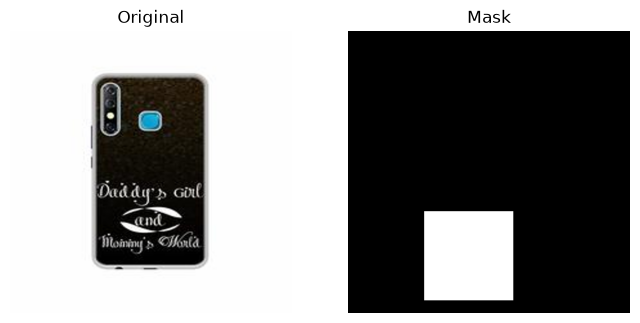

In [20]:
cases = pd.read_csv(DATA / 'test_cases.csv')
required = {'image_id', 'image_path', 'mask_path', 'mask_type'}
assert required.issubset(cases.columns), f'Missing CSV columns: {required - set(cases.columns)}'
assert len(cases) > 0, 'No evaluation cases found'
print('Total cases:', len(cases))
print(cases['mask_type'].value_counts())
display(cases.head())

def load_case(row):
    image = Image.open(DATA / row['image_path']).convert('RGB').resize((512, 512))
    mask = Image.open(DATA / row['mask_path']).convert('L').resize((512, 512), Image.Resampling.NEAREST)
    mask = mask.point(lambda x: 255 if x >= 128 else 0)
    return image, mask

image, mask = load_case(cases.iloc[0])
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(image); ax[0].set_title('Original')
ax[1].imshow(mask, cmap='gray', vmin=0, vmax=255); ax[1].set_title('Mask')
for a in ax: a.axis('off')
plt.show()

## 3. Load BrushNet

For this evaluation, I used the pretrained BrushNet random-mask checkpoint with the Realistic Vision SD1.5 backbone. Since my GPU has 8 GB of VRAM, I used CPU offloading to reduce memory usage. I also disabled the safety checker for local testing, but the generated images still need to be checked before being used publicly.

In [21]:
MODEL_DIR = PAIR / 'models' / 'BrushNet'
BRUSHNET_PATH = MODEL_DIR / 'random_mask_brushnet_ckpt'
BASE_PATH = MODEL_DIR / 'realisticVisionV60B1_v51VAE'
assert BRUSHNET_PATH.is_dir() and BASE_PATH.is_dir(), 'BrushNet model folders not found'

brushnet = BrushNetModel.from_pretrained(str(BRUSHNET_PATH), torch_dtype=torch.float16)
pipe = StableDiffusionBrushNetPipeline.from_pretrained(
    str(BASE_PATH), brushnet=brushnet, torch_dtype=torch.float16,
    low_cpu_mem_usage=False, safety_checker=None, requires_safety_checker=False
)
pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)
pipe.enable_model_cpu_offload()
pipe.safety_checker = None
pipe.requires_safety_checker = False
print('BrushNet loaded')

C:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\Models\Pair_01\models\sources\BrushNet\src\diffusers\models\lora.py:387: FutureWarning: `LoRACompatibleLinear` is deprecated and will be removed in version 1.0.0. Use of `LoRACompatibleLinear` is deprecated. Please switch to PEFT backend by installing PEFT: `pip install peft`.
  deprecate("LoRACompatibleLinear", "1.0.0", deprecation_message)
C:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\Models\Pair_01\models\sources\BrushNet\src\diffusers\models\lora.py:300: FutureWarning: `LoRACompatibleConv` is deprecated and will be removed in version 1.0.0. Use of `LoRACompatibleConv` is deprecated. Please switch to PEFT backend by installing PEFT: `pip install peft`.
  deprecate("LoRACompatibleConv", "1.0.0", deprecation_message)
Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]C:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\Models\Pair_01\models\so

BrushNet loaded


## 4. Evaluation metrics

- **Masked PSNR / SSIM:** compare generated pixels with the ground truth *inside the mask* (higher is better).
- **Masked LPIPS:** perceptual distance on the mask's bounding-box crop, using the same neutral grey outside the selected region (lower is better). This is an approximate region-based LPIPS measure, not pixel-level LPIPS.
- **Unmasked SSIM:** checks how well the model preserves the area that should not change, using the raw model output (higher is better).
- **Runtime:** elapsed inference seconds (lower is better), excluding model loading and metric calculation.

Scores are calculated on the raw generation before compositing, avoiding artificially perfect unmasked preservation. I also saved a pasted image for visual presentation.

In [22]:
lpips_model = lpips.LPIPS(net='alex').eval().cpu()

def scores(original, generated, mask):
    gt = np.asarray(original, dtype=np.float32) / 255
    pred = np.asarray(generated, dtype=np.float32) / 255
    m = np.asarray(mask, dtype=np.uint8) > 0
    if not m.any() or m.all():
        raise ValueError('Mask must contain both black and white pixels')

    # Pixel error inside the masked area
    mse = np.mean((gt[m] - pred[m]) ** 2)
    psnr = float(-10 * np.log10(max(mse, 1e-12)))

    # SSIM computed per pixel, then averaged over each region
    _, ssim_map = structural_similarity(gt, pred, channel_axis=2,
                                         data_range=1.0, full=True)
    if ssim_map.ndim == 3:
        ssim_map = ssim_map.mean(axis=2)
    masked_ssim = float(ssim_map[m].mean())
    unmasked_ssim = float(ssim_map[~m].mean())

    # LPIPS: bounding box around the mask, grey outside the target region
    yy, xx = np.where(m)
    y1, y2 = yy.min(), yy.max() + 1
    x1, x2 = xx.min(), xx.max() + 1
    crop_mask = m[y1:y2, x1:x2, None]
    gt_crop = np.where(crop_mask, gt[y1:y2, x1:x2], 0.5)
    pred_crop = np.where(crop_mask, pred[y1:y2, x1:x2], 0.5)
    def tensor(a):
        return torch.from_numpy(np.ascontiguousarray(a)).permute(2, 0, 1).unsqueeze(0) * 2 - 1
    with torch.no_grad():
        distance = float(lpips_model(tensor(gt_crop), tensor(pred_crop)).item())

    return {'masked_psnr': psnr, 'masked_ssim': masked_ssim,
            'masked_lpips': distance, 'unmasked_ssim': unmasked_ssim,
            'mask_coverage': float(m.mean())}

def generate(image, mask, seed):
    # BrushNet expects the missing part of the image to be black
    arr = np.asarray(image).copy()
    arr[np.asarray(mask) > 0] = 0
    masked_image = Image.fromarray(arr)
    mask_rgb = mask.convert('RGB')

    generator = torch.Generator('cuda' if torch.cuda.is_available() else 'cpu').manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.inference_mode():
        output = pipe(PROMPT, masked_image, mask_rgb,
                      num_inference_steps=STEPS, generator=generator,
                      brushnet_conditioning_scale=1.0).images[0]
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    # Use original pixels outside the mask for the presentation image
    composite = Image.composite(output, image, mask)
    return output, composite, elapsed

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


c:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\.venv-pair1\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\.venv-pair1\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: c:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\.venv-pair1\Lib\site-packages\lpips\weights\v0.1\alex.pth


c:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\.venv-pair1\Lib\site-packages\lpips\lpips.py:107: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  se

## 5. Run evaluation



In [23]:
test_cases = cases.head(LIMIT) if LIMIT is not None else cases
records = []

for i, (_, row) in enumerate(test_cases.iterrows(), 1):
    case_id = f"{row['image_id']}_{row['mask_type']}"
    try:
        original, mask = load_case(row)
        raw, pasted, seconds = generate(original, mask, SEED)
        metrics = scores(original, raw, mask)
        raw.save(OUT / f'{case_id}_raw.png')
        pasted.save(OUT / f'{case_id}.png')
        records.append({'model': 'BrushNet', 'case_id': case_id,
                        'image_id': row['image_id'], 'mask_type': row['mask_type'],
                        'seed': SEED, 'steps': STEPS, 'prompt': PROMPT,
                        'time_seconds': seconds, 'status': 'ok', 'error': '', **metrics})
        print(f'{i}/{len(test_cases)}  {case_id}  {seconds:.1f}s  OK')
    except Exception as e:
        records.append({'model': 'BrushNet', 'case_id': case_id,
                        'image_id': row['image_id'], 'mask_type': row['mask_type'],
                        'seed': SEED, 'steps': STEPS, 'prompt': PROMPT,
                        'status': 'failed', 'error': str(e)})
        print(f'{i}/{len(test_cases)}  {case_id}  FAILED: {e}')
    pd.DataFrame(records).to_csv(OUT / 'metrics.csv', index=False)

results = pd.DataFrame(records)
print('Completed:', (results['status'] == 'ok').sum(), '/', len(results))
display(results.head())

100%|██████████| 20/20 [00:07<00:00,  2.73it/s]


1/300  img_0001_small  8.9s  OK


100%|██████████| 20/20 [00:03<00:00,  6.12it/s]


2/300  img_0001_medium  4.6s  OK


100%|██████████| 20/20 [00:03<00:00,  6.14it/s]


3/300  img_0001_large  4.5s  OK


... (591 outputs left out)

299/300  img_0100_medium  4.9s  OK


100%|██████████| 20/20 [00:03<00:00,  5.51it/s]


300/300  img_0100_large  5.0s  OK
Completed: 300 / 300


,model,case_id,image_id,mask_type,seed,steps,prompt,time_seconds,status,error,masked_psnr,masked_ssim,masked_lpips,unmasked_ssim,mask_coverage
0,BrushNet,img_0001_small,img_0001,small,42,20,a realistic product photograph with clean stud...,8.892905,ok,,12.263792,0.536784,0.329218,0.951962,0.100113
1,BrushNet,img_0001_medium,img_0001,medium,42,20,a realistic product photograph with clean stud...,4.649841,ok,,6.322259,0.118363,0.700473,0.972310,0.250000
2,BrushNet,img_0001_large,img_0001,large,42,20,a realistic product photograph with clean stud...,4.533580,ok,,4.593106,0.220401,0.842141,0.972470,0.400452
3,BrushNet,img_0002_small,img_0002,small,42,20,a realistic product photograph with clean stud...,4.612172,ok,,20.439932,0.789869,0.143232,0.895886,0.100113
4,BrushNet,img_0002_medium,img_0002,medium,42,20,a realistic product photograph with clean stud...,4.515822,ok,,7.200924,0.205065,0.770652,0.919647,0.250000


## 6. Results and examples

The table below reports average performance by mask size. Examples are also given below.

Failures: 0


masked_psnr        masked_ssim        masked_lpips         \
                 mean    std        mean    std         mean    std   
mask_type                                                             
large           8.873  3.128       0.260  0.126        0.735  0.125   
medium          9.882  3.642       0.298  0.158        0.673  0.162   
small          12.919  5.925       0.409  0.245        0.503  0.228   

          unmasked_ssim        time_seconds         
                   mean    std         mean    std  
mask_type                                           
large             0.940  0.048        4.986  0.125  
medium            0.934  0.049        4.984  0.128  
small             0.932  0.046        5.027  0.409

,mean
masked_psnr,10.558
masked_ssim,0.322
masked_lpips,0.637
unmasked_ssim,0.935
time_seconds,4.999


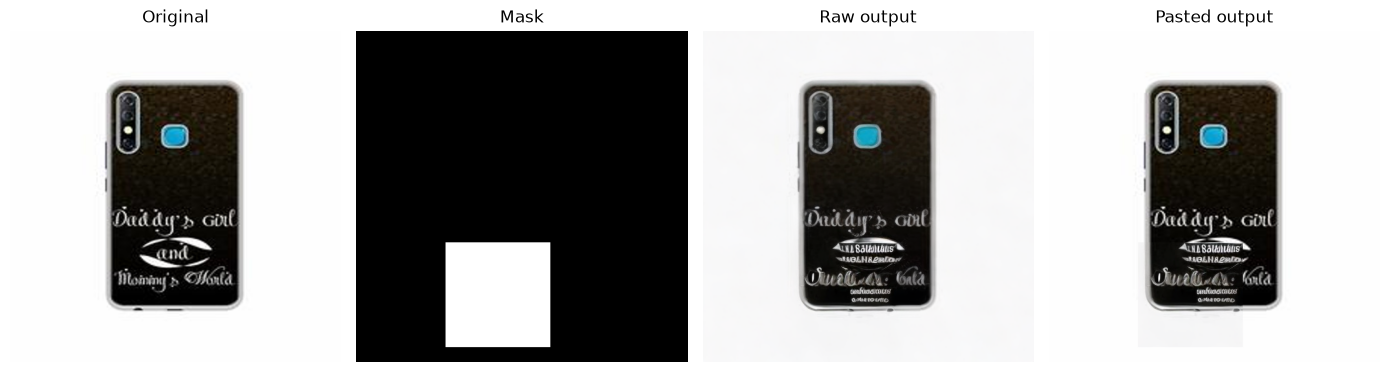

In [24]:
good = results[results['status'] == 'ok'].copy()
print('Failures:', (results['status'] != 'ok').sum())
if not good.empty:
    columns = ['masked_psnr', 'masked_ssim', 'masked_lpips', 'unmasked_ssim', 'time_seconds']
    display(good.groupby('mask_type')[columns].agg(['mean', 'std']).round(3))
    display(good[columns].mean().round(3).to_frame('mean'))

    # Show the first successful case
    sample = good.iloc[0]
    row = cases[(cases['image_id'] == sample['image_id']) &
                (cases['mask_type'] == sample['mask_type'])].iloc[0]
    original, mask = load_case(row)
    raw = Image.open(OUT / f"{sample['case_id']}_raw.png")
    pasted = Image.open(OUT / f"{sample['case_id']}.png")
    fig, ax = plt.subplots(1, 4, figsize=(14, 4))
    for a, im, title in zip(ax, [original, mask, raw, pasted],
                            ['Original', 'Mask', 'Raw output', 'Pasted output']):
        a.imshow(im, cmap='gray' if title == 'Mask' else None)
        a.set_title(title)
        a.axis('off')
    plt.tight_layout()
    plt.savefig(OUT / 'example_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()

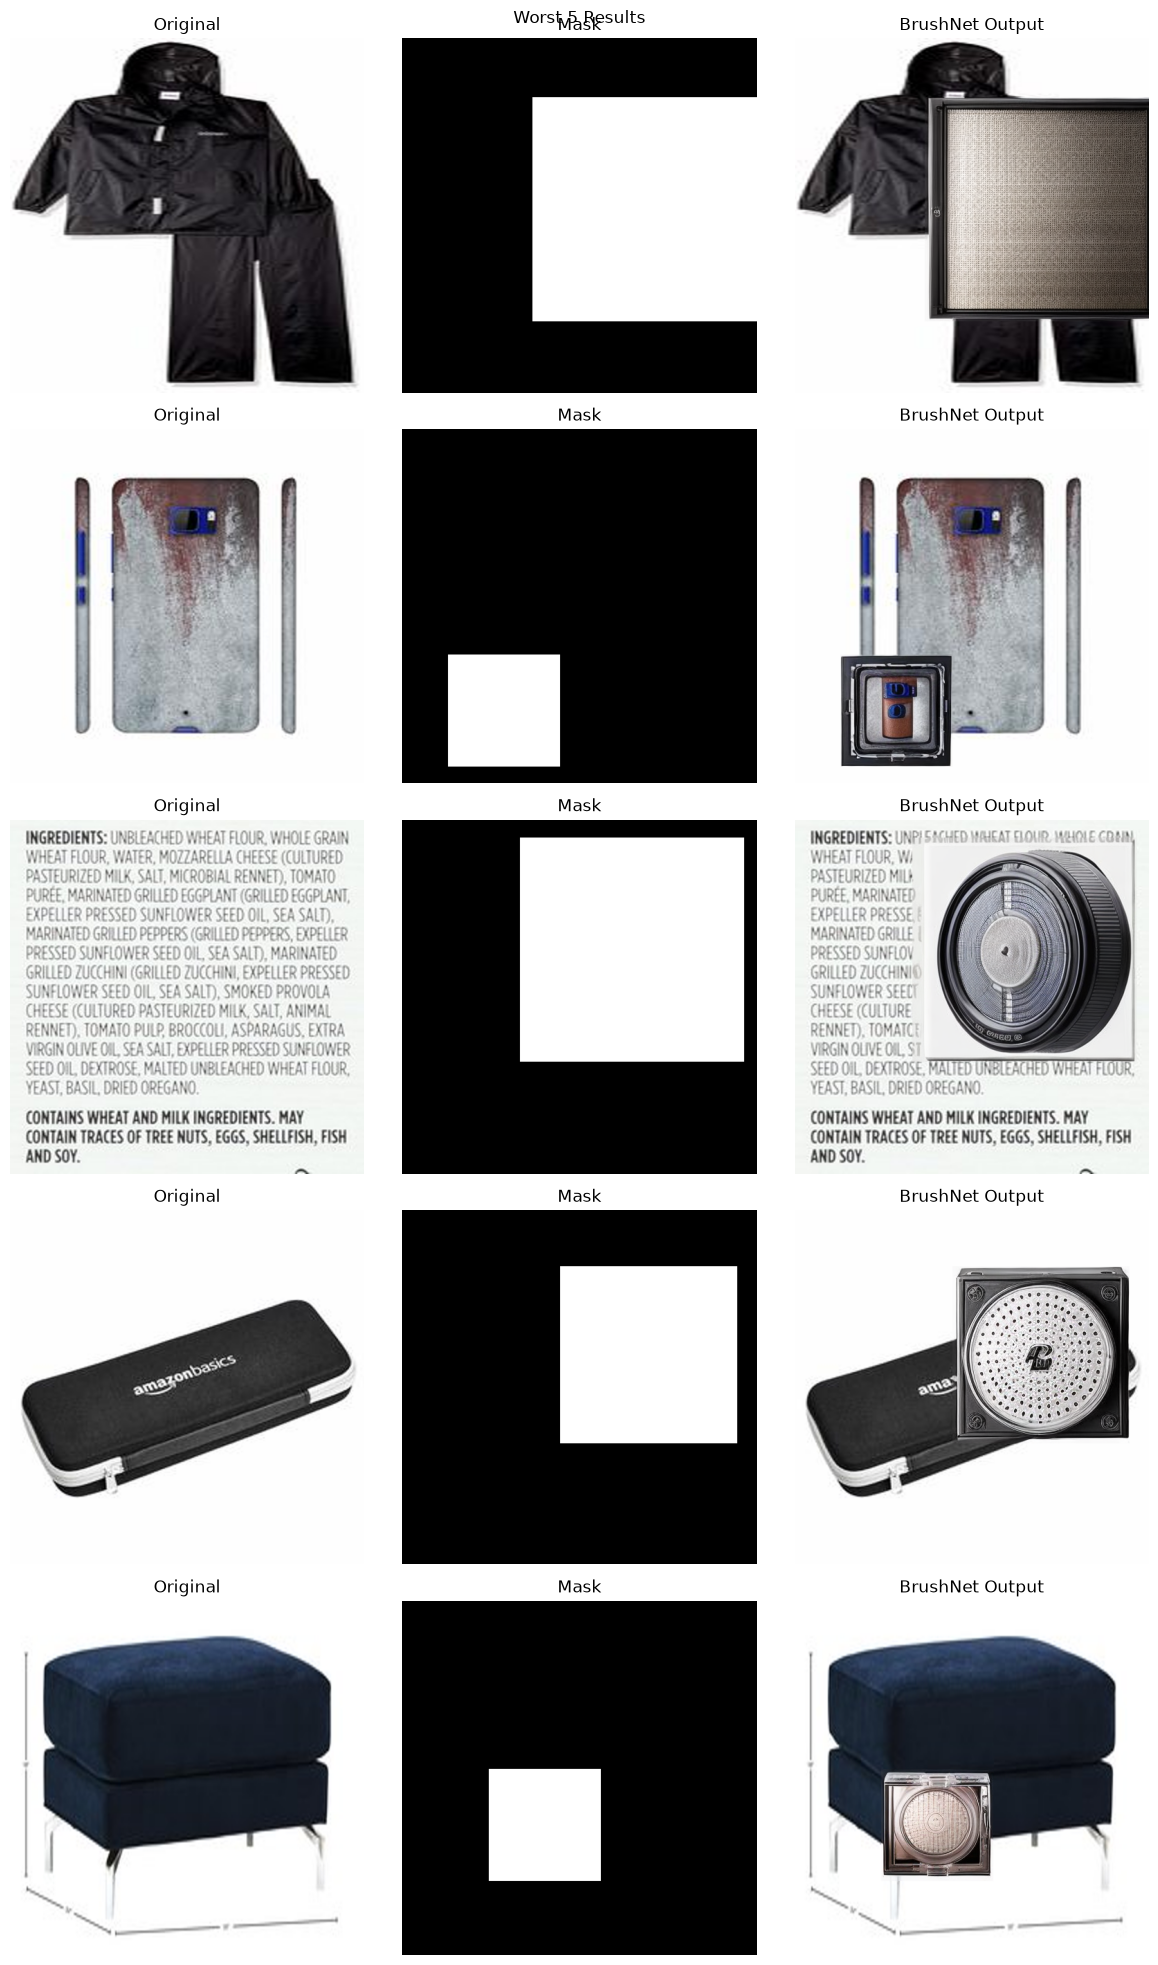

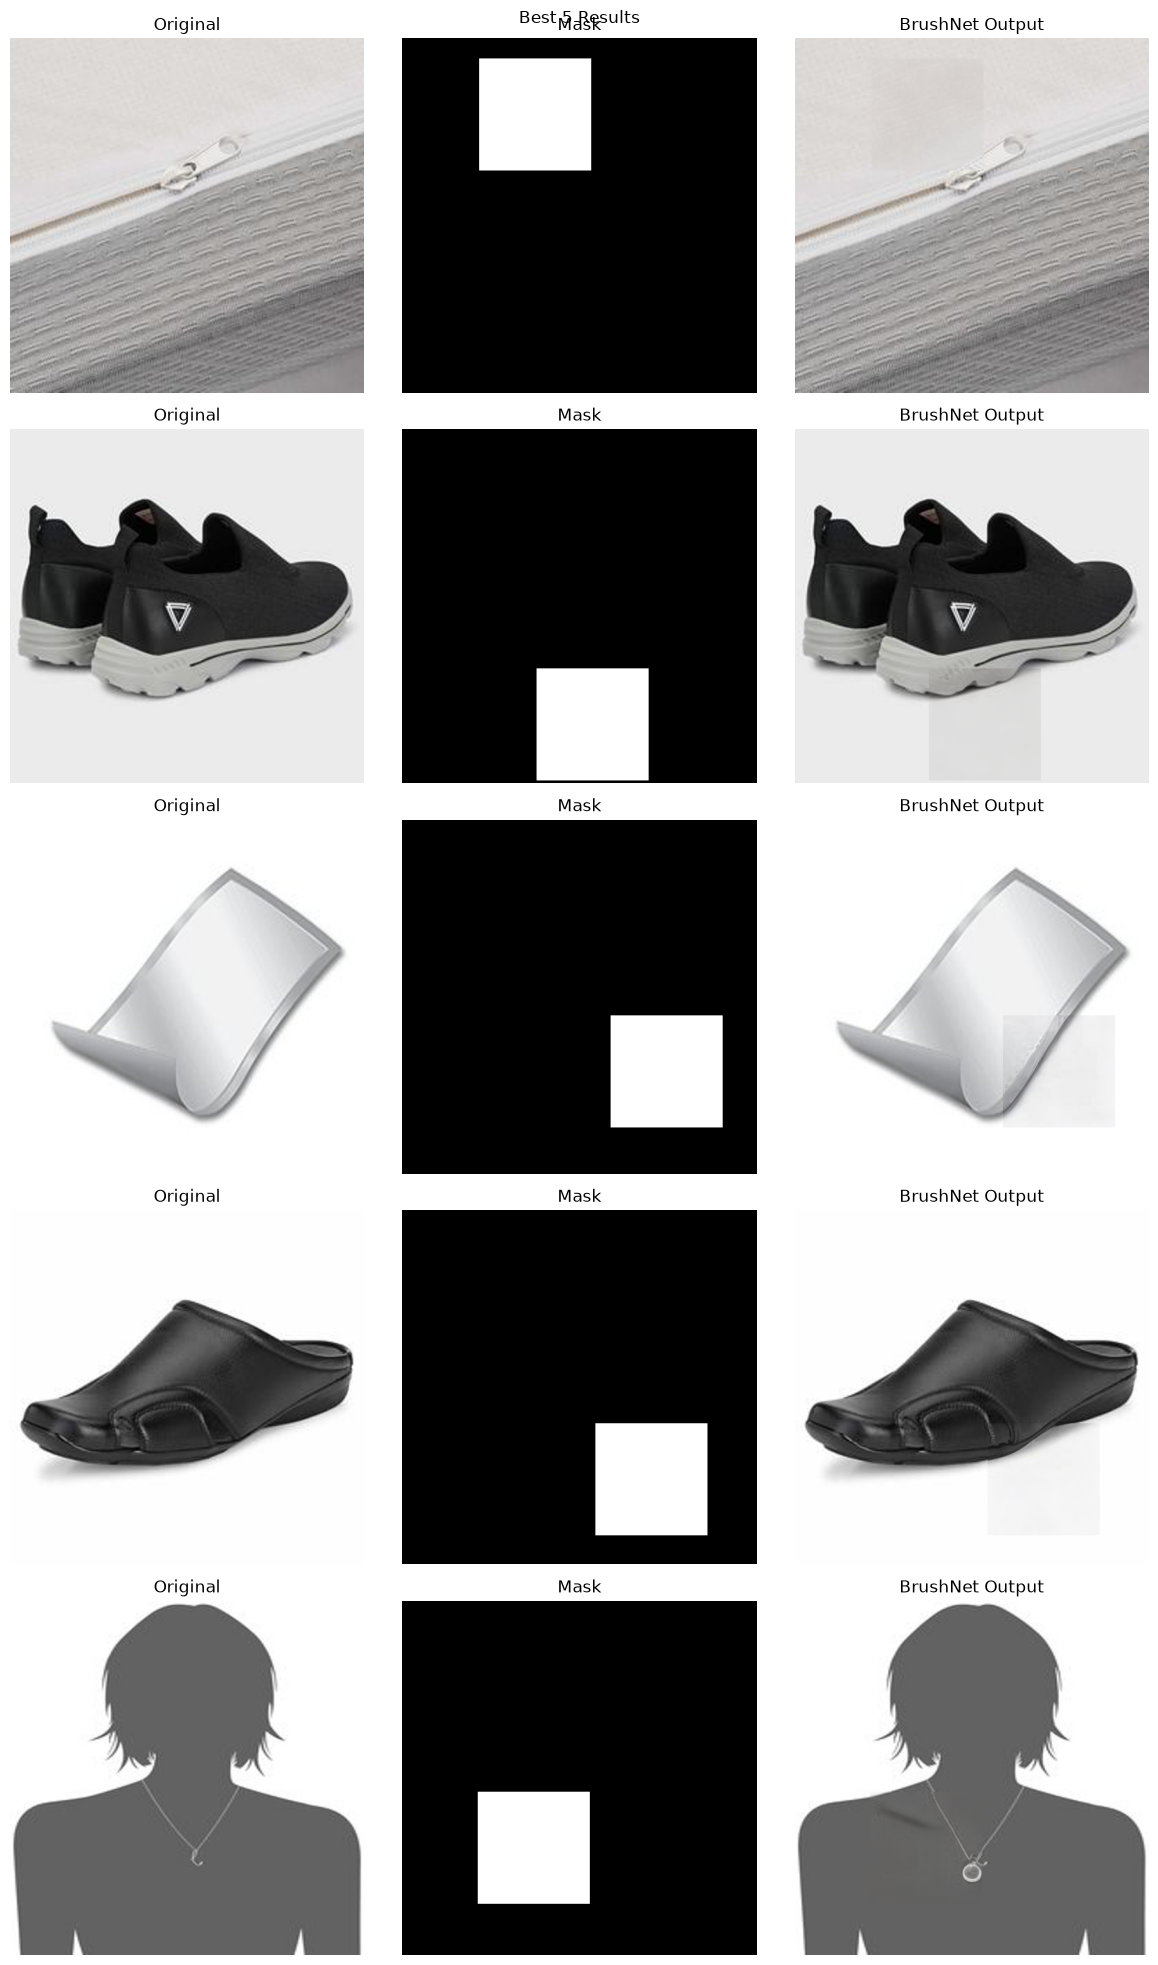

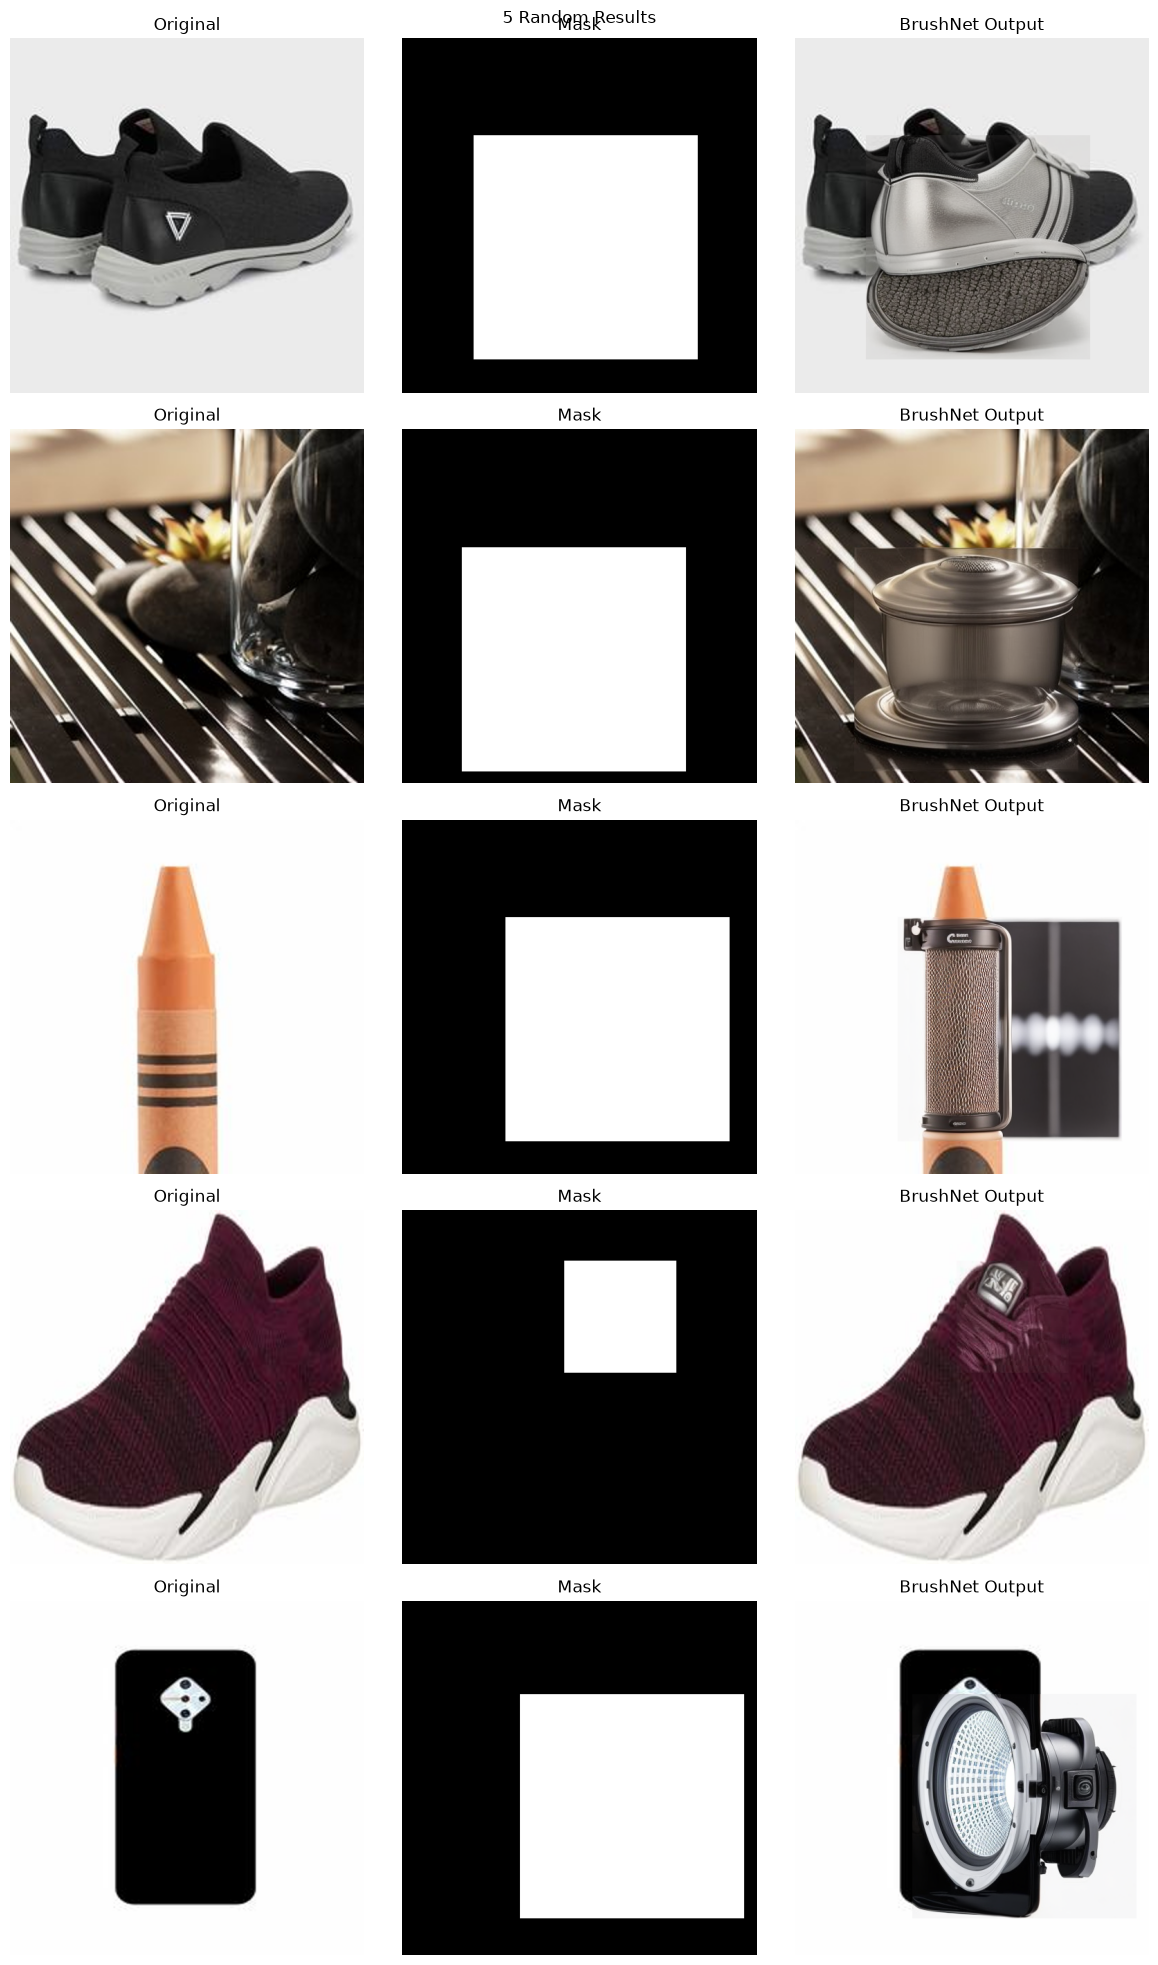

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Load results and dataset information
results = pd.read_csv("results/BrushNet/metrics.csv")
cases = pd.read_csv("datasets/test_cases.csv")

results = results.merge(cases[["image_id", "mask_type", "image_path", "mask_path"]],
                        on=["image_id", "mask_type"])

# Select examples
worst = results.nsmallest(5, "masked_ssim")
best = results.nlargest(5, "masked_ssim")
random_examples = results.sample(5, random_state=42)

def show_examples(examples, title):
    fig, axes = plt.subplots(len(examples), 3, figsize=(12, 4 * len(examples)))

    for i, (_, row) in enumerate(examples.iterrows()):
        original = Image.open(Path("datasets") / row["image_path"])
        mask = Image.open(Path("datasets") / row["mask_path"])
        output = Image.open(Path("results/BrushNet") / f"{row['case_id']}.png")

        for ax, img, label in zip(
            axes[i],
            [original, mask, output],
            ["Original", "Mask", "BrushNet Output"]
        ):
            ax.imshow(img, cmap="gray" if label == "Mask" else None)
            ax.set_title(label)
            ax.axis("off")

        axes[i, 0].set_ylabel(f"SSIM: {row['masked_ssim']:.3f}\nLPIPS: {row['masked_lpips']:.3f}")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_examples(worst, "Worst 5 Results")
show_examples(best, "Best 5 Results")
show_examples(random_examples, "5 Random Results")

## 7. Notes for comparison and reflection

The results show that BrushNet performs better with smaller masks. Small masks achieved the highest masked SSIM (0.409) and PSNR (12.919), while large masks had the lowest scores. This suggests that BrushNet struggles more when a larger part of the original image is missing.

From the visual examples, some outputs look very similar to the original images, especially when the masked area contains a simple background. However, several unsuccessful examples show that BrushNet generates completely different objects instead of reconstructing the missing parts. For example, it generated electronic or mechanical objects over clothing, shoes and other products. These outputs may look realistic individually, but they do not match the original products.

The unmasked SSIM was relatively high (0.935), meaning most areas outside the masks were preserved. The average inference time was approximately 5 seconds per image.

For Amazon product images, these results suggest that BrushNet may be useful for small background corrections, but it is less reliable for reconstructing important product details. Incorrectly generated objects could misrepresent products to customers. I will compare these results with PowerPaint to determine which model produces more accurate and consistent inpainting results.